In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
df = pd.read_csv('city_sales_data.csv')

In [ ]:
print("Dataset Shape:", df.shape)
df_clean = df.drop_duplicates()
print(df_clean)     

Dataset Shape: (12000, 17)
           Order_ID       Date         City State   Region Store_Type  \
0      ORD-20240001 2024-04-12        Miami    FL    South   Flagship   
1      ORD-20240002 2024-05-10  Los Angeles    CA     West   Standard   
2      ORD-20240003 2025-11-12      Seattle    WA     West    Express   
3      ORD-20240004 2025-01-22     Columbus    OH  Midwest    Express   
4      ORD-20240005 2024-02-04     Columbus    OH  Midwest   Standard   
...             ...        ...          ...   ...      ...        ...   
11995  ORD-20251996 2024-06-25       Denver    CO     West    Express   
11996  ORD-20251997 2025-05-02      Seattle    WA     West   Standard   
11997  ORD-20251998 2024-04-19      Houston    TX    South     Outlet   
11998  ORD-20251999 2024-12-12     New York    NY     East    Express   
11999  ORD-20252000 2025-03-27  San Antonio    TX    South   Standard   

              Category                 Product  Quantity  Unit_Price  \
0             Clothing  

In [5]:
print(df.head())

       Order_ID        Date         City State   Region Store_Type  \
0  ORD-20240001  2024-04-12        Miami    FL    South   Flagship   
1  ORD-20240002  2024-05-10  Los Angeles    CA     West   Standard   
2  ORD-20240003  2025-11-12      Seattle    WA     West    Express   
3  ORD-20240004  2025-01-22     Columbus    OH  Midwest    Express   
4  ORD-20240005  2024-02-04     Columbus    OH  Midwest   Standard   

         Category                 Product  Quantity  Unit_Price  Discount  \
0        Clothing      Thermal Base Layer         2       34.92      0.00   
1       Furniture     Modern Coffee Table         1      198.42      0.05   
2        Clothing           Cotton Hoodie         2       48.18      0.00   
3       Furniture  Ergonomic Office Chair         1      296.76      0.00   
4  Home & Kitchen            Air Fryer XL         2      109.17      0.05   

   Total_Sales  Total_Cost  Profit Payment_Method Customer_Type  \
0        69.84        24.0   45.84     Debit Card

In [6]:
missing_counts = df.isnull().sum()
print(missing_counts)

Order_ID           0
Date               0
City               0
State              0
Region             0
Store_Type         0
Category           0
Product            0
Quantity           0
Unit_Price         0
Discount           0
Total_Sales        0
Total_Cost         0
Profit             0
Payment_Method     0
Customer_Type      0
Customer_Rating    0
dtype: int64


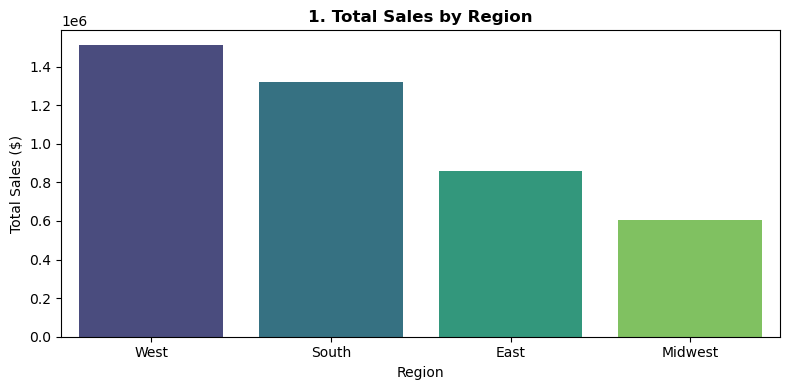

In [69]:
# total sales vs Region
plt.figure(figsize=(8, 4))
region_sales = df.groupby('Region')['Total_Sales'].sum().reset_index().sort_values(by='Total_Sales', ascending=False)
sns.barplot(data=region_sales, x='Region', y='Total_Sales', hue='Region', palette='viridis')
plt.title('1. Total Sales by Region', fontsize=12, fontweight='bold')
plt.ylabel('Total Sales ($)')
plt.tight_layout()
plt.show()

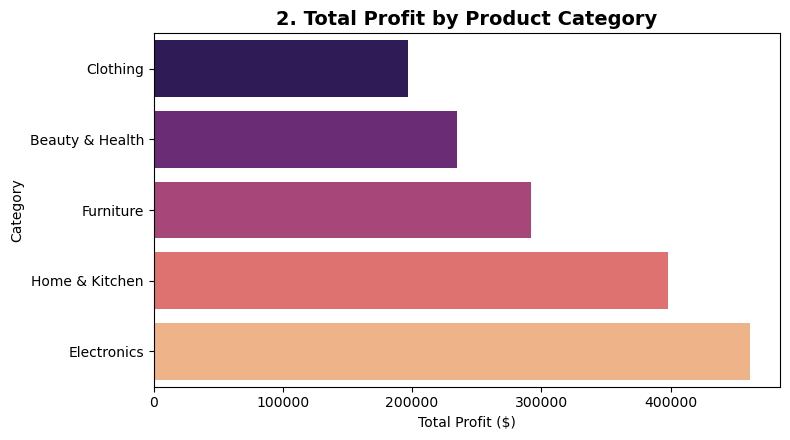

In [25]:
#Total Profit vs Product Category

plt.figure(figsize=(8, 4.5))
cat_profit = df.groupby('Category')['Profit'].sum().reset_index().sort_values(by='Profit', ascending=True)
sns.barplot(data=cat_profit, y='Category', x='Profit', hue='Category', legend=False, palette='magma')
plt.title('2. Total Profit by Product Category', fontsize=14, fontweight='bold')
plt.xlabel('Total Profit ($)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

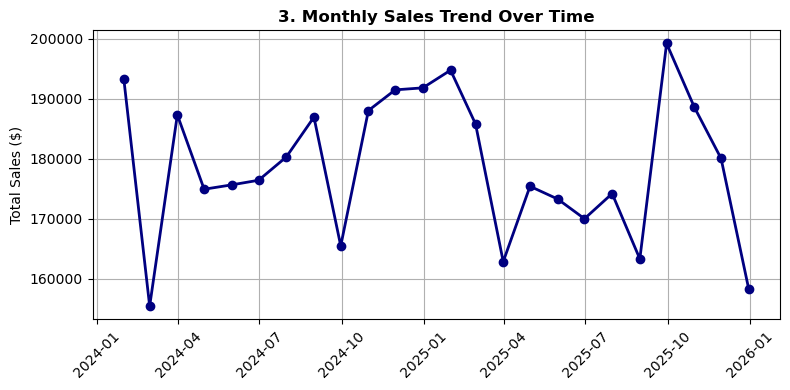

In [ ]:
# Monthly Sales Trend Over Time
df['Date'] = pd.to_datetime(df['Date'])
df_monthly = df.set_index('Date').resample('ME')['Total_Sales'].sum().reset_index()

plt.figure(figsize=(8, 4))
plt.plot(df_monthly['Date'], df_monthly['Total_Sales'], marker='o', color='Navy', linewidth=2)
plt.title('3. Monthly Sales Trend Over Time', fontsize=12, fontweight='bold')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid()
plt.show()

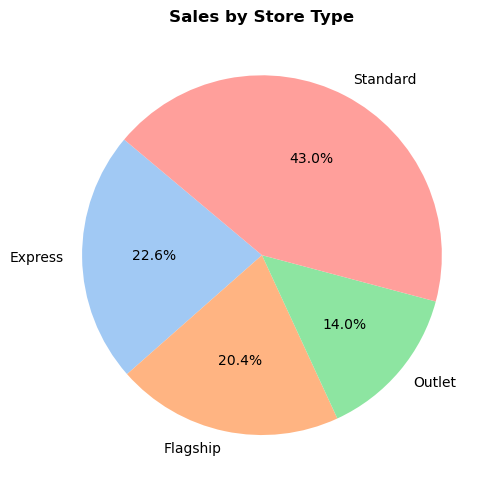

In [42]:
plt.figure(figsize=(6, 5))
store_sales = df.groupby('Store_Type')['Total_Sales'].sum()
plt.pie(store_sales, labels=store_sales.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Sales by Store Type', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

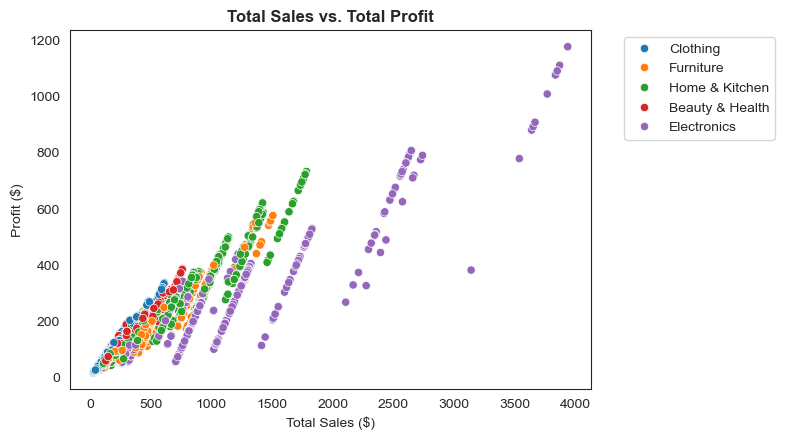

In [130]:
#Total Sales vs. Total Profit
sns.set_style('white')
plt.figure(figsize=(8, 4.5))
sns.scatterplot(data=df, x='Total_Sales', y='Profit', hue='Category', palette='tab10')
plt.title('Total Sales vs. Total Profit', fontsize=12, fontweight='bold')
plt.xlabel('Total Sales ($)')
plt.ylabel('Profit ($)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

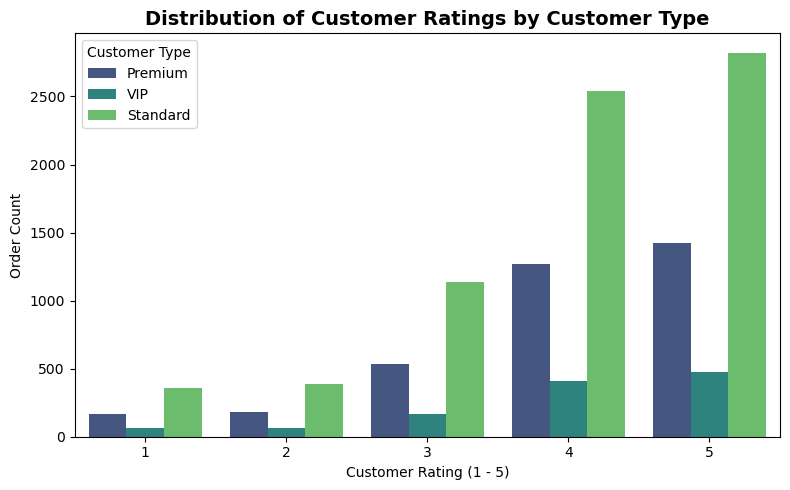

In [68]:
#Distribution of Customer Ratings
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Customer_Rating', hue='Customer_Type', palette='viridis')
plt.title('Distribution of Customer Ratings by Customer Type', fontsize=14, fontweight='bold')
plt.xlabel('Customer Rating (1 - 5)')
plt.ylabel('Order Count')
plt.legend(title='Customer Type')
plt.tight_layout()
plt.show()

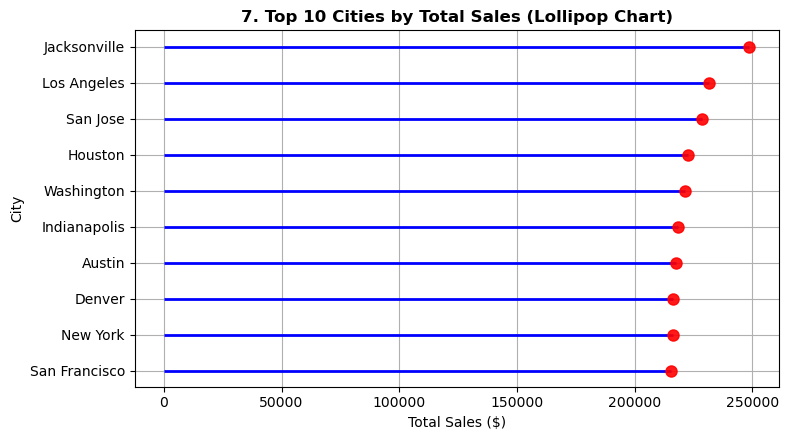

In [86]:
#Top 10 Cities by Total Sales
plt.figure(figsize=(8, 4.5))
plt.hlines(y=top_cities['City'], xmin=0, xmax=top_cities['Total_Sales'], color='blue', linewidth=2)
plt.plot(top_cities['Total_Sales'], top_cities['City'], "o", markersize=8, color='red', alpha=0.9)
plt.title('7. Top 10 Cities by Total Sales (Lollipop Chart)', fontsize=12, fontweight='bold')
plt.xlabel('Total Sales ($)')
plt.ylabel('City')
plt.grid()
plt.tight_layout()
plt.show()

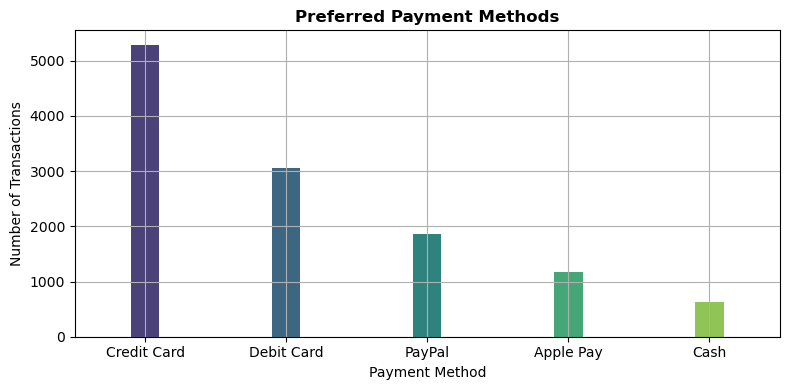

In [95]:
# Preferred Payment method
plt.figure(figsize=(8, 4))
payment_counts = df['Payment_Method'].value_counts().reset_index()
payment_counts.columns = ['Payment_Method', 'Count']
sns.barplot(data=payment_counts, x='Payment_Method', y='Count', hue='Payment_Method', palette='viridis', width=0.2,)
plt.title('Preferred Payment Methods', fontsize=12, fontweight='bold')
plt.xlabel('Payment Method')
plt.ylabel('Number of Transactions')
plt.tight_layout()
plt.grid()
plt.show()

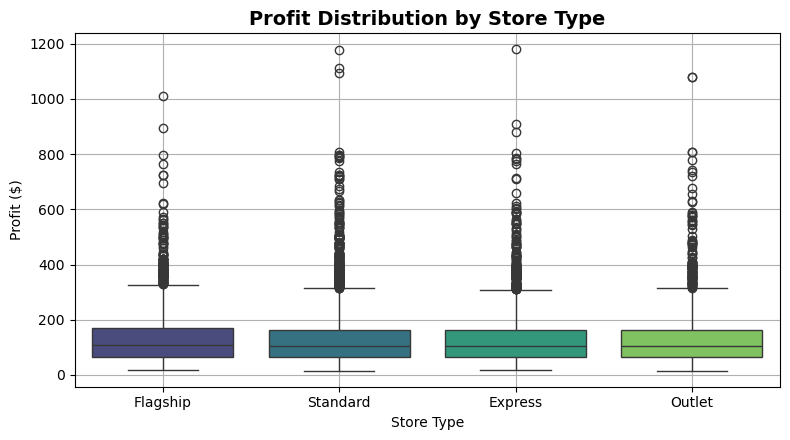

In [ ]:
# Profit Distribution by Store Type 
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df, x='Store_Type', y='Profit', hue='Store_Type', palette='viridis')
plt.title('Profit Distribution by Store Type', fontsize=14, fontweight='bold')
plt.xlabel('Store Type')
plt.ylabel('Profit ($)')
plt.tight_layout()
plt.grid()
plt.show()

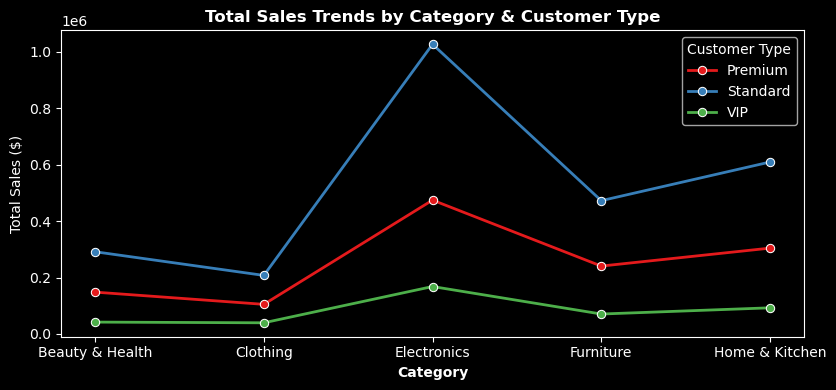

In [117]:
# Total Sales Trends by Category & Customer Type
plt.style.use('dark_background')
plt.figure(figsize=(8.5, 4))
cat_cust_sales = df.groupby(['Category', 'Customer_Type'])['Total_Sales'].sum().reset_index()

sns.lineplot(data=cat_cust_sales, x='Category', y='Total_Sales', hue='Customer_Type', palette='Set1', marker='o', linewidth=2,)

plt.title('Total Sales Trends by Category & Customer Type', fontsize=12, fontweight='bold')
plt.xlabel('Category', fontweight='bold')
plt.ylabel('Total Sales ($)')
plt.legend(title='Customer Type')
plt.tight_layout()
plt.show()

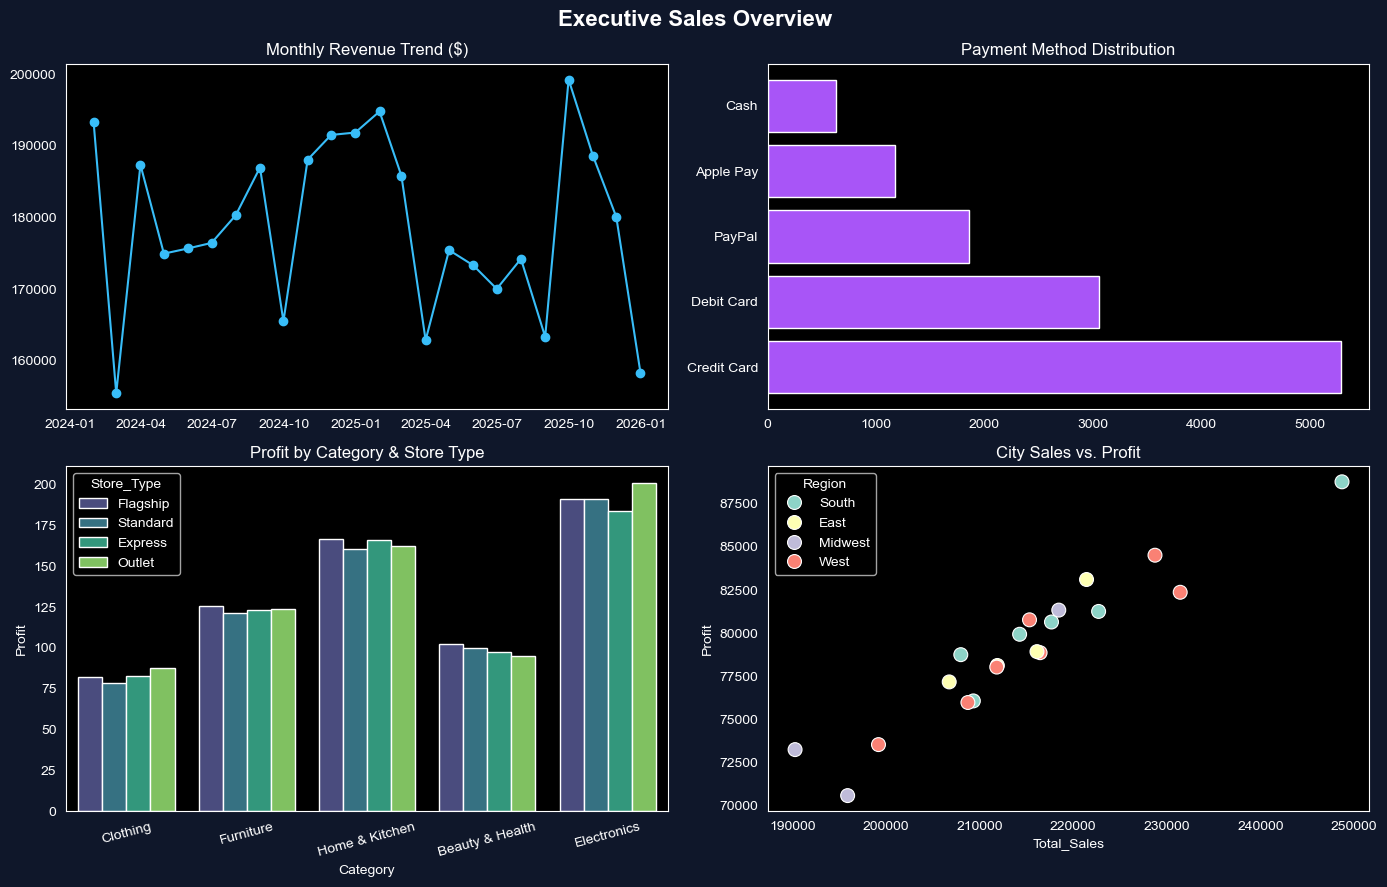

In [139]:
#DASHBOARD
plt.style.use('dark_background')
fig, axes = plt.subplots(2, 2, figsize=(14, 9), facecolor='#0f172a')
fig.suptitle(
    'Executive Sales Overview', fontsize=16, fontweight='bold', color='white'
)
# 1. Line Chart: Monthly Revenue
monthly = df.set_index('Date').resample('ME')['Total_Sales'].sum()
axes[0, 0].plot(monthly.index, monthly.values, marker='o', color='#38bdf8')
axes[0, 0].set_title('Monthly Revenue Trend ($)')

# 2. Horizontal Bar Chart: Payment Methods
pay = df['Payment_Method'].value_counts()
axes[0, 1].barh(pay.index, pay.values, color='#a855f7')
axes[0, 1].set_title('Payment Method Distribution')

# 3. Grouped Bar Chart: Profit by Category & Store Type
sns.barplot(
    data=df,
    x='Category',
    y='Profit',
    hue='Store_Type',
    palette='viridis',
    ax=axes[1, 0],
    errorbar=None,
)
axes[1, 0].set_title('Profit by Category & Store Type')
axes[1, 0].tick_params(axis='x', rotation=15)

# 4. Scatter Plot: Sales vs Profit by City
city_df = (
    df.groupby('City')
    .agg({'Total_Sales': 'sum', 'Profit': 'sum', 'Region': 'first'})
    .reset_index()
)
sns.scatterplot(
    data=city_df,
    x='Total_Sales',
    y='Profit',
    hue='Region',
    s=100,
    ax=axes[1, 1],
)
axes[1, 1].set_title('City Sales vs. Profit')

plt.tight_layout()
plt.show()

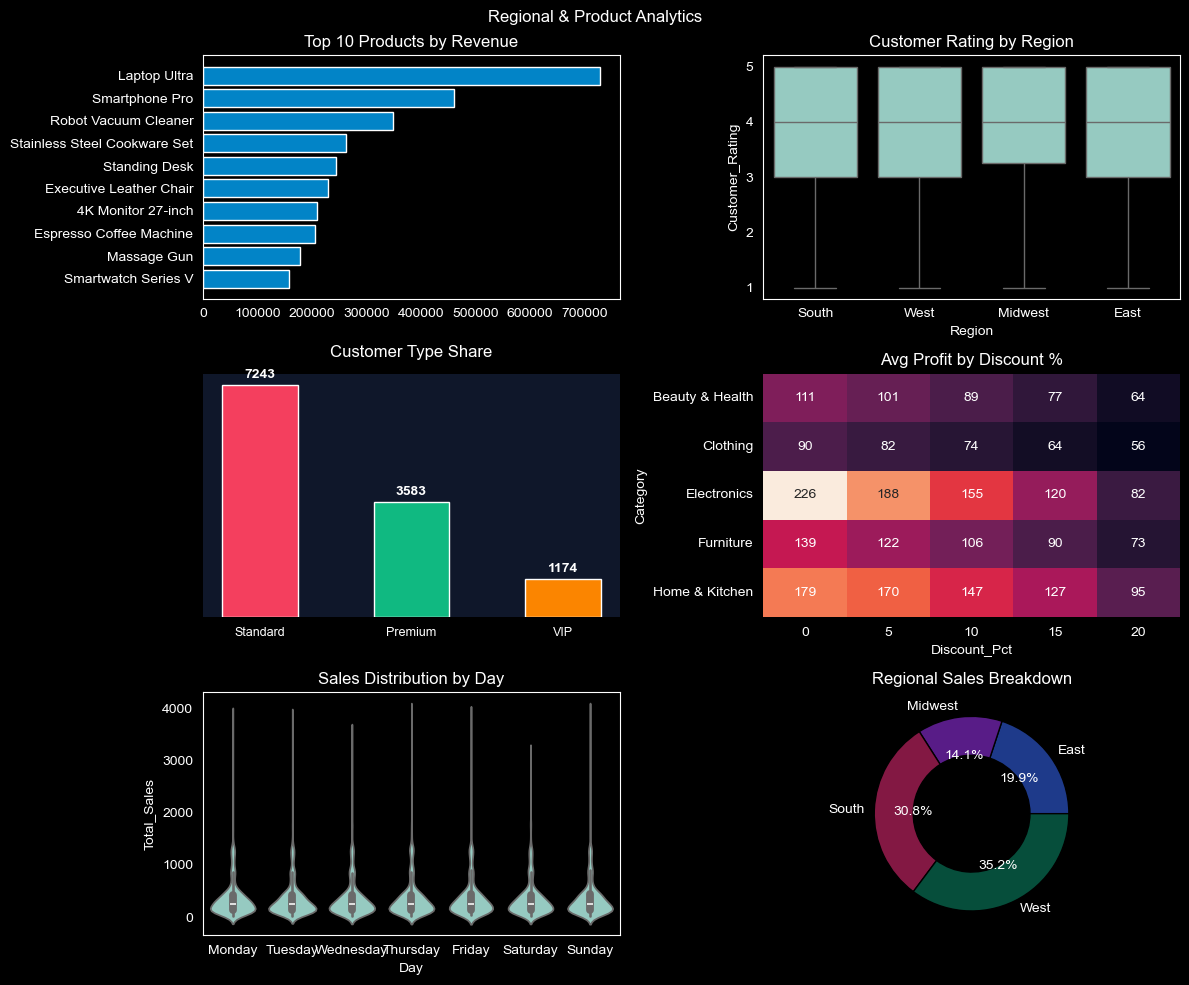

In [151]:
# Dashboard 2

fig, axes = plt.subplots(3, 2, figsize=(12, 10))
fig.suptitle('Regional & Product Analytics')

# 1. Top 10 Products
top_p = df.groupby('Product')['Total_Sales'].sum().nlargest(10).sort_values()
axes[0, 0].barh(top_p.index, top_p.values, color='#0284c7')
axes[0, 0].set_title('Top 10 Products by Revenue')

# 2. Ratings by Region
sns.boxplot(data=df, x='Region', y='Customer_Rating', ax=axes[0, 1])
axes[0, 1].set_title('Customer Rating by Region')

# 3. Customer Type Share
axes[1, 0].remove()
ax = fig.add_subplot(3, 2, 3, facecolor='#0f172a')
counts = df['Customer_Type'].value_counts()

bars = ax.bar(counts.index, counts.values, color=['#f43f5e', '#10b981', '#fb8500'], width=0.5)
ax.bar_label(bars, fmt='%d', padding=3, color='white', fontweight='bold')

ax.set_title('Customer Type Share', color='white', pad=12)
ax.tick_params(colors='white', labelsize=9)
ax.spines[:].set_visible(False)
ax.set_yticks([])

# 4. Discount vs Profit Heatmap
df['Discount_Pct'] = (df['Discount'] * 100).astype(int)
pivot = df.pivot_table(
    index='Category', columns='Discount_Pct', values='Profit', aggfunc='mean'
)
sns.heatmap(pivot, annot=True, fmt='.0f', cbar=False, ax=axes[1, 1])
axes[1, 1].set_title('Avg Profit by Discount %')

# 5. Sales by Day of Week
df['Day'] = df['Date'].dt.day_name()
days = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday',
]
sns.violinplot(data=df, x='Day', y='Total_Sales', order=days, ax=axes[2, 0])
axes[2, 0].set_title('Sales Distribution by Day')

# 6. Regional Revenue Share (Dark Donut Chart)
region_sales = df.groupby('Region')['Total_Sales'].sum()
dark_colors = ['#1e3a8a', '#581c87', '#831843', '#064e3b', '#78350f']
axes[2, 1].pie(
    region_sales,
    labels=region_sales.index,
    autopct='%1.1f%%',
    colors=dark_colors,
    wedgeprops=dict(width=0.4, edgecolor='black'),
)
axes[2, 1].set_title('Regional Sales Breakdown')

plt.tight_layout()
plt.show()